# Pricing and Delta Hedging a GBP/USD Option Through the September 2022 Mini-Budget

## Background
In September 2022 I'd just started sixth form and watched sterling fall sharply after the UK mini-budget, without understanding what was happening in markets. Having since learned the basics of options and hedging, I wanted to go back to that episode.

## Question 
How effective is delta hedging for a GBP/USD option during a period of extreme exchange-rate volatility?

In this project, we approach this by pricing a one-month GBP put with Garman–Kohlhagen (the FX equivalent to Black-Scholes). Then, we delta-hedge it daily through September 2022, and compare the actual hedging error with Monte Carlo simulations of the same strategy, giving us a model-based benchmark for comparison.

## Data

First, we pull the required data for the project. The analysis uses three daily series from **July to October 2022** to cover the period before, during and after the mini-budget:

- `DEXUSUK` - GBP/USD spot exchange rate from FRED. This is the value of £1 in US dollars, recorded at noon in New York each trading day.
- `DFF` - US effective federal funds rate from FRED. This is the actual overnight interest rate at which US banks lend reserve balances to one another.
- `IUDBEDR` - UK Bank Rate from the Bank of England. This is the UK's main policy interest rate. It only changed twice in this window, so it is entered by hand from the decision dates (4 August and 22 September 2022).

All series are aligned to GBP/USD trading days. July and August provide enough history to calculate the 21-day volatility estimate at the start of September. We now import the relevant libraries for the project and pull the series data. In the following table, the spot exchange rate is denoted as $S$, the US interest rate as $r_d$ (domestic) and the UK interest rate as $r_f$ (foreign), with both rates expressed as decimals. A plot of GBP/USD against the time frame of July-October 2022 is also plotted below. 

In [9]:
import io, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq

In [ ]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}&cosd=2022-07-01&coed=2022-10-31" # template URL for FRED data

spot = pd.read_csv(url.format("DEXUSUK"), index_col=0, parse_dates=True, na_values=".").dropna() # request GBP/USD data 
effr = pd.read_csv(url.format("DFF"), index_col=0, parse_dates=True) # request USD interest rate data 

df = spot.rename(columns={"DEXUSUK": "S"}) # rename DEXUSUK to S
df["r_usd"] = effr["DFF"].reindex(df.index) / 100 # match USD-rate data to dates in df and convert to decimal

# bank rate: 1.25% until 3/8, 1.75% from 4/8, 2.25% from 22/9
df["r_gbp"] = 0.0125
df.loc["2022-08-04":, "r_gbp"] = 0.0175
df.loc["2022-09-22":, "r_gbp"] = 0.0225 # manually set GBP interest rate 

df 

,S,r_usd,r_gbp
observation_date,,,
2022-07-01,1.2048,0.0158,0.0125
2022-07-05,1.1932,0.0158,0.0125
2022-07-06,1.1907,0.0158,0.0125
2022-07-07,1.1994,0.0158,0.0125
2022-07-08,1.2036,0.0158,0.0125
...,...,...,...
2022-10-25,1.1469,0.0308,0.0225
2022-10-26,1.1615,0.0308,0.0225
2022-10-27,1.1574,0.0308,0.0225


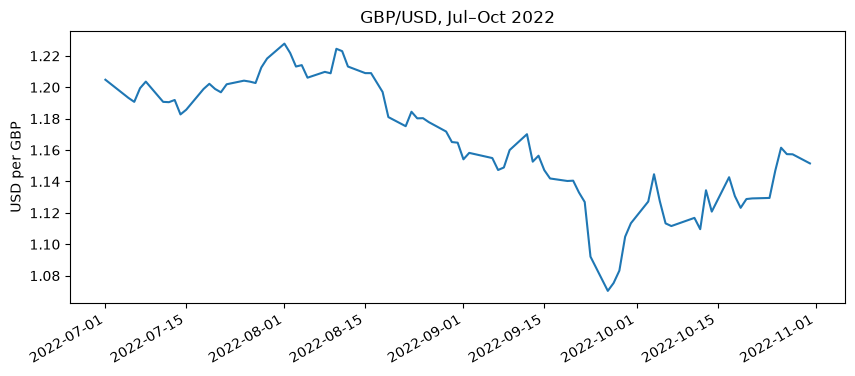

In [13]:
df["S"].plot(figsize=(10, 4), title="GBP/USD, Jul–Oct 2022", ylabel="USD per GBP", xlabel="")
plt.show()

From the plot, GBP/USD declined from around 1.22 in August to 1.14 in early September. Following the mini-budget, the exchange rate fell sharply to around 1.07 before slowly recovering to 1.13 by early October. The option studied in this project runs from 1 September to 3 October, capturing the full episode: the initial decline, the mini-budget shock, and the subsequent recovery. We now cover the options pricing models used in this project: Black-Scholes and Garman-Kohlhagen.

## Black–Scholes and Garman–Kohlhagen

Options are priced using Black–Scholes, adapted to FX through the Garman–Kohlhagen model. We first recap Black–Scholes, then show the change needed for currencies.

### Black–Scholes Model

Black–Scholes prices a European option on a non-dividend-paying stock, with these main assumptions:

- The stock price follows a geometric Brownian motion with constant volatility $\sigma$ and a constant risk-free rate $r$.
- The option can be replicated by continuously trading the stock and a risk-free bond.

With spot $S$, strike $K$ and time to expiry $T$ in years:

$$
C = S\,N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S\,N(-d_1)
$$

$$
d_1 = \frac{\ln(S/K) + \left(r + \tfrac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$

where:
- $C$ and $P$ are the call and put prices
- $d_1$ and $d_2$ measure how far spot is from the strike in units of total volatility $\sigma\sqrt{T}$
- $N(\cdot)$ is the standard normal CDF.

Black–Scholes assumes a single risk-free rate $r$. In FX, both currencies have their own interest rates, so the model needs to account for the differential between them. Garman–Kohlhagen extends Black–Scholes to do exactly this.

### Garman–Kohlhagen Model

Holding a foreign currency earns that currency's interest rate, in the same way that holding a stock earns a dividend yield. So an FX option depends on two rates:

- $r_d$: the domestic rate (here USD, since GBP/USD is quoted in USD per GBP)
- $r_f$: the foreign rate (here GBP)

The prices of a call and a put (in USD per GBP) become

$$
C = S e^{-r_f T} N(d_1) - K e^{-r_d T} N(d_2)
$$

$$
P = K e^{-r_d T} N(-d_2) - S e^{-r_f T} N(-d_1)
$$

$$
d_1 = \frac{\ln(S/K) + \left(r_d - r_f + \tfrac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$

Setting $r_f = 0$ recovers Black–Scholes.

The option studied here is a GBP put / USD call: it pays off if sterling falls below the strike, which is the protection a UK importer with a dollar bill needs.

As a check, the prices should satisfy put–call parity:

$$
C - P = S e^{-r_f T} - K e^{-r_d T}
$$

### Garman Kohlhagen Function

We now implement the Garman–Kohlhagen formulas as a function that returns the price of a call or put. To check the implementation, we price both with the same inputs and test put–call parity: the left-hand side $C - P$ should equal the right-hand side $S e^{-r_f T} - K e^{-r_d T}$ exactly. The inputs are illustrative values close to GBP/USD at the start of September 2022. As we can see, both sides of put–call parity match, so the pricer is consistent.

In [16]:
def gk_price(S, K, T, r_d, r_f, sigma, kind="put"):
    d1 = (np.log(S / K) + (r_d - r_f + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    if kind == "call":
        return S * np.exp(-r_f * T) * norm.cdf(d1) - K * np.exp(-r_d * T) * norm.cdf(d2)
    return K * np.exp(-r_d * T) * norm.cdf(-d2) - S * np.exp(-r_f * T) * norm.cdf(-d1)


# Put–call parity check
S, K, T, r_d, r_f, sigma = 1.16, 1.16, 1/12, 0.0233, 0.0175, 0.10

C = gk_price(S, K, T, r_d, r_f, sigma, "call")
P = gk_price(S, K, T, r_d, r_f, sigma, "put")

print(C - P, S * np.exp(-r_f * T) - K * np.exp(-r_d * T))

0.0005597143484861178 0.0005597143484861178


We now have the option price, which tells us its value, but we also want to know how that value changes when the underlying inputs change. We now look at the Greeks which measure these sensitivities.

## Greeks

The Greeks measure how the option's price responds to changes in its inputs. For the GBP put, with $n(\cdot)$ the standard normal PDF:

- Delta: the change in price per unit change in spot

$$
\Delta = -e^{-r_f T} N(-d_1)
$$

- Gamma: the change in delta per unit change in spot

$$
\Gamma = \frac{e^{-r_f T} n(d_1)}{S \sigma \sqrt{T}}
$$

- Vega: the change in price per unit change in volatility

$$
\nu = S e^{-r_f T} n(d_1) \sqrt{T}
$$

- Theta: the change in price as time passes

Delta drives the hedge: the seller holds $\Delta$ units of GBP against the option. Gamma determines how quickly that hedge goes out of date as spot moves.

To check the formulas, each Greek is compared with a finite-difference estimate: nudge one input slightly, reprice, and measure the change.

In [18]:
def gk_put_greeks(S, K, T, r_d, r_f, sigma):
    d1 = (np.log(S / K) + (r_d - r_f + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    delta = -np.exp(-r_f * T) * norm.cdf(-d1)
    gamma = np.exp(-r_f * T) * norm.pdf(d1) / (S * sigma * np.sqrt(T))
    vega  = S * np.exp(-r_f * T) * norm.pdf(d1) * np.sqrt(T)
    theta = (-S * np.exp(-r_f * T) * norm.pdf(d1) * sigma / (2 * np.sqrt(T))
             - r_f * S * np.exp(-r_f * T) * norm.cdf(-d1)
             + r_d * K * np.exp(-r_d * T) * norm.cdf(-d2))
    return delta, gamma, vega, theta


# Finite-difference check: nudge one input, reprice, measure the change
h = 1e-4
fd_delta = (gk_price(S+h, K, T, r_d, r_f, sigma) - gk_price(S-h, K, T, r_d, r_f, sigma)) / (2*h)
fd_gamma = (gk_price(S+h, K, T, r_d, r_f, sigma) - 2*gk_price(S, K, T, r_d, r_f, sigma) + gk_price(S-h, K, T, r_d, r_f, sigma)) / h**2
fd_vega  = (gk_price(S, K, T, r_d, r_f, sigma+h) - gk_price(S, K, T, r_d, r_f, sigma-h)) / (2*h)
fd_theta = -(gk_price(S, K, T+h, r_d, r_f, sigma) - gk_price(S, K, T-h, r_d, r_f, sigma)) / (2*h)

print("Analytical: ", np.round(gk_put_greeks(S, K, T, r_d, r_f, sigma), 6))
print("Finite diff:", np.round((fd_delta, fd_gamma, fd_vega, fd_theta), 6))

Analytical:  [-0.486854 11.89045   0.133332 -0.076419]
Finite diff: [-0.486854 11.890441  0.133332 -0.076419]


## The Trade

We now set up the option that the rest of the project follows. On the first trading day of September 2022, a UK importer that owes $10m in one month buys a GBP put / USD call from a bank, which sells it and delta-hedges it. 

The terms are fixed by simple rules rather than chosen with hindsight:

- Dates: inception on 1 September 2022, expiry on 3 October 2022 (the first trading days of each month)
- Volatility: $\sigma$ is the annualised standard deviation of the 21 daily log returns up to inception, held fixed for the option's life
- Strike: at-the-money forward, $K = F = S_0 e^{(r_d - r_f)T}$
- Notional: sized to cover \$10m, so the GBP notional is $N = 10{,}000{,}000 / K$
- Time: measured in trading days, $T = \text{number of trading days} / 252$

With an ATM-forward strike, put–call parity gives $C = P$, a useful check that the setup is right.

In [19]:
t0, tT = "2022-09-01", "2022-10-03"           # inception and expiry
trade = df.loc[t0:tT]                         # the option's life

S0 = trade["S"].iloc[0]
r_d = trade["r_usd"].iloc[0]
r_f = trade["r_gbp"].iloc[0]
T = (len(trade) - 1) / 252                    # trading days to expiry, in years

log_ret = np.log(df["S"]).diff()
sigma = log_ret.loc[:t0].tail(21).std() * np.sqrt(252)

K = S0 * np.exp((r_d - r_f) * T)              # ATM-forward strike
N = 10_000_000 / K                            # GBP notional

P0 = gk_price(S0, K, T, r_d, r_f, sigma, "put")
C0 = gk_price(S0, K, T, r_d, r_f, sigma, "call")
premium_usd = N * P0

print(f"S0 = {S0:.4f}, K = {K:.4f}, sigma = {sigma:.2%}, T = {T:.4f}")
print(f"Put = {P0:.5f}, Call = {C0:.5f} USD per GBP")
print(f"Premium = ${premium_usd:,.0f} (£{premium_usd / S0:,.0f})")

S0 = 1.1541, K = 1.1547, sigma = 9.08%, T = 0.0833
Put = 0.01205, Call = 0.01205 USD per GBP
Premium = $104,318 (£90,389)


At inception, spot is 1.1541 and the ATM-forward strike is 1.1547. The 21-day historical volatility is 9.08%, reflecting a relatively calm August, and this is the volatility the option is priced and hedged with for its whole life. The put and call prices are equal, as put–call parity requires for an ATM-forward strike. The premium is \$104,318 (about £90,400), roughly 1% of the \$10m notional.

## Delta Hedge

Now the bank sold the put, so it loses money if sterling falls. To offset this, it holds $\Delta$ units of GBP per unit of notional. Since the put's delta is negative, this means a short sterling position that gains as sterling falls. Small moves in spot then roughly cancel between the option and the hedge.

Under the model's assumptions, rebalancing continuously would replicate the option exactly: the premium received would be precisely enough to cover the payoff. In practice the hedge is rebalanced once a day, so between rebalances the hedge goes out of date. How much it drifts depends on gamma and on the size of each day's move. The leftover gain or loss at expiry is the hedging error.

The hedge works as follows:

1. Inception: receive the premium in USD, and sell $|N\Delta|$ GBP at spot. The proceeds go into a USD cash account.
2. Daily: the USD cash earns $r_d$ and the GBP position accrues $r_f$. Then recompute delta with the new spot and one day less to expiry, and trade GBP to match it.
3. Expiry: close the GBP position and pay the put's payoff, $N \max(K - S_T, 0)$.

The cash left over is the hedging error in USD. A perfect hedge would leave exactly zero. Volatility and interest rates are held at their inception values throughout, as the model assumes.

The same function is used for both simulated and real spot paths, so the two are compared on identical terms.

In [20]:
def delta_hedge(path, K, r_d, r_f, sigma, N):
    dt = 1 / 252
    n = len(path) - 1                                   # number of trading days

    # Inception: receive premium, set up the hedge
    delta = gk_put_greeks(path[0], K, n*dt, r_d, r_f, sigma)[0]
    hedge = N * delta                                   # GBP held (negative = short)
    cash = N * gk_price(path[0], K, n*dt, r_d, r_f, sigma) - hedge * path[0]

    # Each day: accrue interest, then rebalance
    for i in range(1, n + 1):
        cash *= np.exp(r_d * dt)
        hedge *= np.exp(r_f * dt)
        if i < n:
            new_hedge = N * gk_put_greeks(path[i], K, (n-i)*dt, r_d, r_f, sigma)[0]
            cash -= (new_hedge - hedge) * path[i]       # buy/sell GBP at today's spot
            hedge = new_hedge

    # Expiry: close the hedge, pay the option
    cash += hedge * path[-1]
    cash -= N * max(K - path[-1], 0)
    return cash                                          # hedging error in USD